# **CA4** - Telecom Customer Churn Classification

# **Group 6** - Narges Zareigolbaghi & Kachina Aschenberg Øwre 
# **Kaggle names** - nargeszareigolbaghi & kachasch

RULES AND CONTEXT OF THE COMPETITION

1. The general workflow is similar to that of CA3. As opposed to CA3, however, you are now expected to use cross-validation instead of multiple train/validation splits. You can use the scikit-learn implementations for cross-validation.

2. You have access to a range of classifiers, kernels, and L1/L2-regularisation covered in DAT200. These can be combined freely. You can also use the ensemble models presented in the lectures. Use the corresponding scikit-learn implementations.

3. Classifier selection and hyperparameter tuning are the core of this exercise. You are expected to make use of all of the following components:

   - Hyperparameter tuning (using scikit-learn tools from Chapter 6)
   - Scikit-learn Pipelines
   - Cross-validation
   - Some form of dimension reduction (e.g. PCA or SFS)
   - A confusion matrix for your final classifier, using a 60/40 train-test split on the entire training dataset
   - Macro-averaged F1-score as the primary evaluation metric (other metrics are encouraged too)

   You must build at least two pipelines combining preprocessing with a classifier. One pipeline must use a kernel, one must use regularisation, and at least one must include a dimension reduction step.

4. You may try other models. If your best-performing Kaggle submission is not one of the two mandatory pipelines, also provide the code for training, tuning, and prediction for that classifier.

5. You may engineer new features if you wish.

6. If you are unsure how to structure your notebook, follow these steps:
   Imports → Read the data → Data exploration & visualisation → Data cleaning → Data exploration & visualisation after cleaning → Preprocessing → Evaluating models/hyperparameters (cross-validation) → Kaggle submission.

DATA DESCRIPTION

The dataset contains information about the customers of a mobile phone operator. Each row is one customer. The features are:

   - CustomerId – unique ID of the customer (not a feature for modelling)
   - State – US state where the customer lives (two-letter code)
   - AccountLength – how long the customer has had an account
   - AreaCode – telephone area code of the customer
   - InternationalPlan – whether the customer has an international calling plan (yes/no)
   - VoiceMailPlan – whether the customer has a voice mail plan (yes/no)
   - NumVoiceMailMessages – number of voice mail messages
   - DayMinutes, DayCalls, DayCharge – total minutes, number of calls and total charge for daytime calls
   - EveMinutes, EveCalls, EveCharge – the same for evening calls
   - NightMinutes, NightCalls, NightCharge – the same for night calls
   - IntlMinutes, IntlCalls, IntlCharge – the same for international calls
   - CustomerServiceCalls – number of calls the customer has made to customer service

Target variable: Churn
   - 0 = customer stays
   - 1 = customer leaves the company

BACKGROUND

You have been hired by a mobile phone operator in the United States. The company is experiencing customer churn, where customers cancel their subscription and move to a competing operator. Retaining existing customers is often significantly cheaper than acquiring new ones.

Your task is to develop a machine learning model capable of predicting whether a customer will leave the company based on information about their subscription plan and phone usage. Accurate churn prediction models allow companies to identify customers who may leave and take proactive measures to retain them.

### 1. Imports

In [1]:
import numpy as np                 # numbers and arrays
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # basic plotting
import seaborn as sns              # nicer statistical plots on top of matplotlib
import sklearn as skl              # machine learning library

from sklearn.model_selection import train_test_split # splits data into training and test sets
from sklearn.preprocessing import StandardScaler # rescales features to have mean 0 and variance 1
from sklearn.linear_model import Perceptron, LogisticRegression # linear classifiers, baseline for comparison and neural networks
from sklearn.svm import SVC     # support vector machine, a more powerful linear classifier (linear or non-linea with a kernel)
from sklearn.tree import DecisionTreeClassifier # decision tree, a non-linear classifier
from sklearn.ensemble import RandomForestClassifier     # random forest, a more powerful non-linear classifier
from sklearn.neighbors import KNeighborsClassifier  # k-nearest neighbors, a non-linear classifier

### 2. Reading data

In [2]:
train = pd.read_csv("trainCA4DAT200.csv")                 # 19 features + CustomerId + Churn labels
test = pd.read_csv("testCA4DAT200.csv")                   # 19 features + CustomerId - no Churn labels 
sample = pd.read_csv("sample_submissionCA4DAT200.csv")    # the format Kaggle expects
print("train:", train.shape, " test:", test.shape, " sample:", sample.shape)
# training data has 3500 rows x 21 columns

# The feature columns: everything except the target (Churn) and CustomerId
print(train.head())
features = [col for col in train.columns if col not in ("Churn", "CustomerId")]
print(len(features), "features:", features)

train: (3500, 21)  test: (1500, 20)  sample: (1500, 2)
   CustomerId State  AccountLength  AreaCode InternationalPlan VoiceMailPlan  \
0      952920    NJ             87       510                no            no   
1      895150    RI            114       510                no           yes   
2      636987    ND             55       415                no            no   
3      538188    DC            100       510               yes            no   
4      947531    AL             74       408                no           yes   

   NumVoiceMailMessages  DayMinutes  DayCalls  DayCharge  ...  EveCalls  \
0                     0       223.2       109      37.94  ...        86   
1                    28       225.8        94      38.39  ...       117   
2                     0       180.1        77      30.62  ...        98   
3                     0        68.5       110      11.65  ...       115   
4                    46       277.7       109      47.21  ...       114   

   EveCharge 

### 3. Data exploration and visualisation

In [3]:
# Explore the training set
train.info()                       # shows entries, column types and memory usage
display(train.describe().T)              # Summary statistics # .T turns the table: one row per feature
print(train["Churn"].value_counts())  # Count of customers who stay (0) or leave (1)
print("Missing values:", train.isnull().sum().sum()) # total number of missing values in the training set
print("Duplicate rows (ignoring CustomerId):", train.duplicated(subset=features + ["Churn"]).sum()) # count of duplicate rows in the training set, ignoring the Id column
# there are no missing values or duplicated rows
# The churn classes are imbalanced:
#  0    3005
# 1     495
# A classifier that predicts Churn =0 only, could have high accuracy just due to imbalance (Remedy by macro-averaged F1)

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerId            3500 non-null   int64  
 1   State                 3500 non-null   str    
 2   AccountLength         3500 non-null   int64  
 3   AreaCode              3500 non-null   int64  
 4   InternationalPlan     3500 non-null   str    
 5   VoiceMailPlan         3500 non-null   str    
 6   NumVoiceMailMessages  3500 non-null   int64  
 7   DayMinutes            3500 non-null   float64
 8   DayCalls              3500 non-null   int64  
 9   DayCharge             3500 non-null   float64
 10  EveMinutes            3500 non-null   float64
 11  EveCalls              3500 non-null   int64  
 12  EveCharge             3500 non-null   float64
 13  NightMinutes          3500 non-null   float64
 14  NightCalls            3500 non-null   int64  
 15  NightCharge           3500 non-n

,count,mean,std,min,25%,50%,75%,max
CustomerId,3500.0,545925.360857,261478.546087,101267.0,322381.00,536375.50,775246.7500,999391.00
AccountLength,3500.0,99.996571,39.471509,1.0,73.00,100.00,126.0000,243.00
AreaCode,3500.0,436.915429,42.169180,408.0,415.00,415.00,415.0000,510.00
NumVoiceMailMessages,3500.0,8.112000,13.728371,0.0,0.00,0.00,19.0000,52.00
DayMinutes,3500.0,180.292429,53.764503,0.0,143.70,179.70,216.5250,351.50
DayCalls,3500.0,100.016286,19.852587,0.0,87.00,100.00,113.0000,163.00
DayCharge,3500.0,30.650306,9.139923,0.0,24.43,30.55,36.8125,59.76
EveMinutes,3500.0,200.763000,50.561814,0.0,165.90,201.05,235.2250,361.80
EveCalls,3500.0,100.178000,19.800506,0.0,87.00,100.00,113.0000,170.00
EveCharge,3500.0,17.065066,4.297740,0.0,14.10,17.09,19.9925,30.75


Churn
0    3005
1     495
Name: count, dtype: int64
Missing values: 0
Duplicate rows (ignoring CustomerId): 0


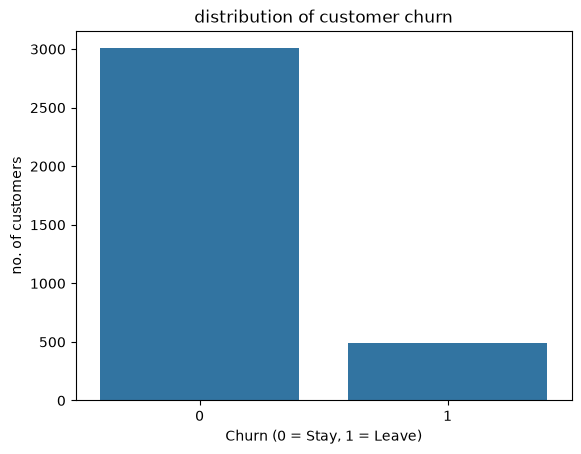

In [4]:
# distribution of Churn
sns.countplot(data=train, x="Churn")
plt.xlabel("Churn (0 = Stay, 1 = Leave)")
plt.ylabel("no. of customers")
plt.title("distribution of customer churn")
plt.show()
# The Churn distribution is highly imbalanced towards more stays 0  

In [5]:
# inspecting datatypes and features
for col in train.columns:
    print(col, train[col].dtype, train[col].nunique()) # train[col].nunique() counts the distinct values in the column
# AreaCode: categorical with integer datatype, 3 categories (408, 415, 510)

# Define categorical features
categorical_features = ["State", "AreaCode", "InternationalPlan", "VoiceMailPlan"]

# Define numerical features
numeric_features = []
for col in train.columns:
    if col not in categorical_features + ["CustomerId", "Churn"]:
        numeric_features.append(col)

CustomerId int64 3500
State str 51
AccountLength int64 211
AreaCode int64 3
InternationalPlan str 2
VoiceMailPlan str 2
NumVoiceMailMessages int64 45
DayMinutes float64 1689
DayCalls int64 118
DayCharge float64 1689
EveMinutes float64 1631
EveCalls int64 120
EveCharge float64 1455
NightMinutes float64 1616
NightCalls int64 129
NightCharge float64 944
IntlMinutes float64 162
IntlCalls int64 20
IntlCharge float64 162
CustomerServiceCalls int64 10
Churn int64 2


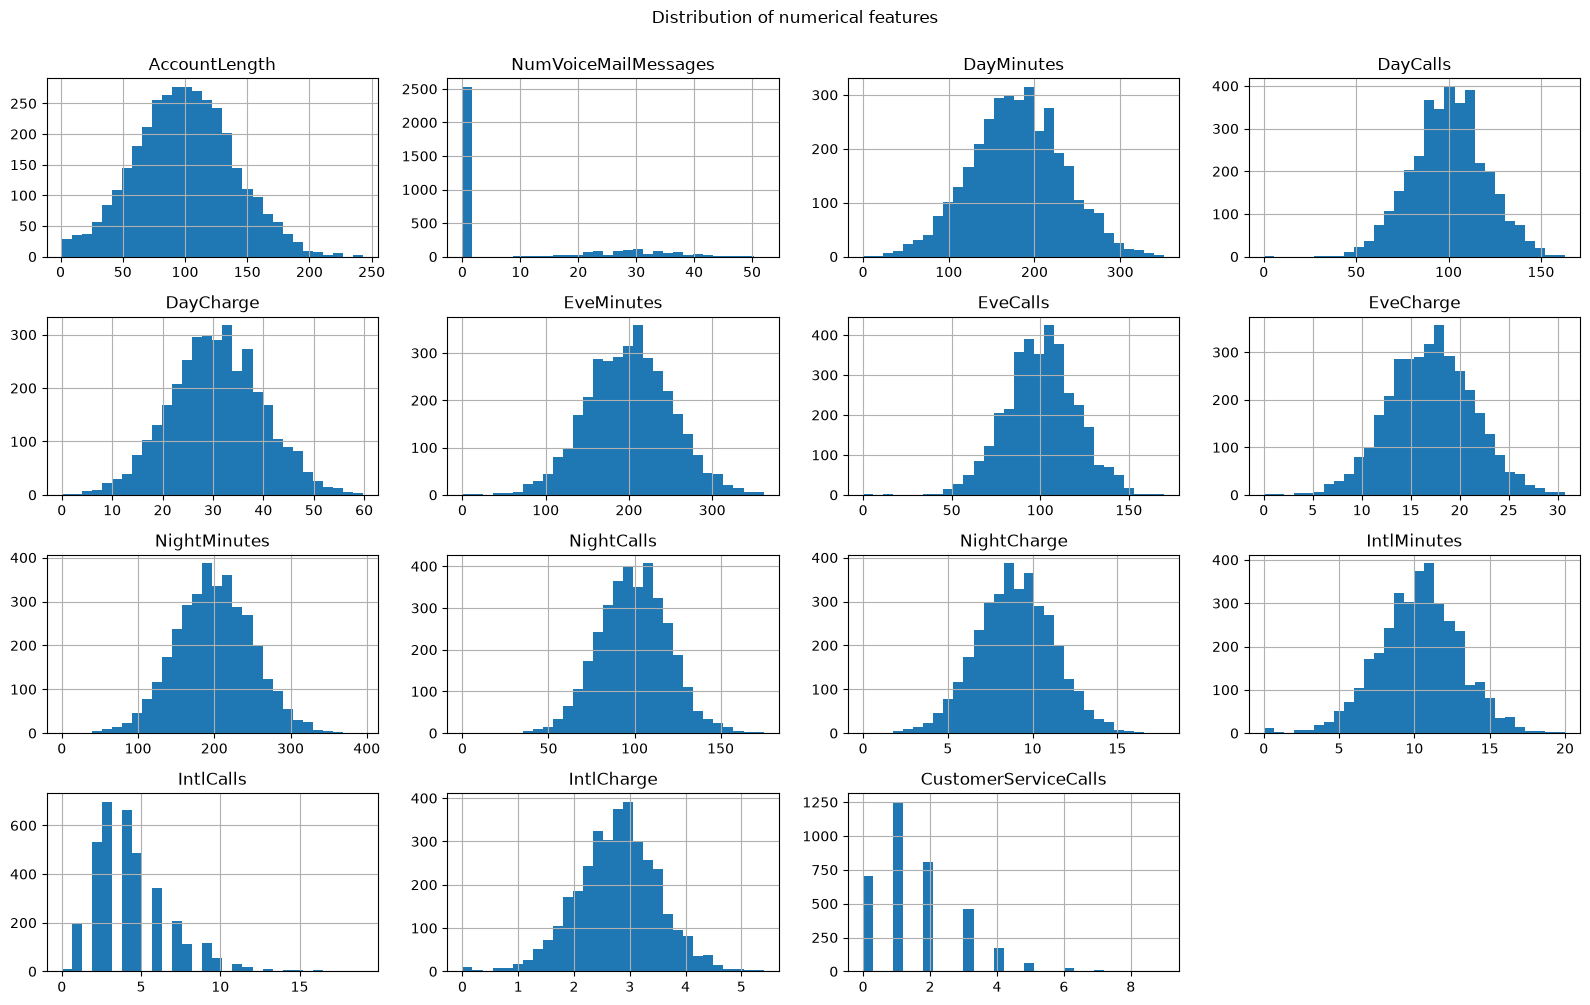

In [6]:
# Visualize the distribution of numerical features
train[numeric_features].hist(figsize=(16, 10), bins=30)

plt.suptitle("Distribution of numerical features", y=1.00)
plt.tight_layout()
plt.show()

# many 0 values in NumVoiceMailMessages
# IntlCalls & CustomerServiceCalls are right-skewed 


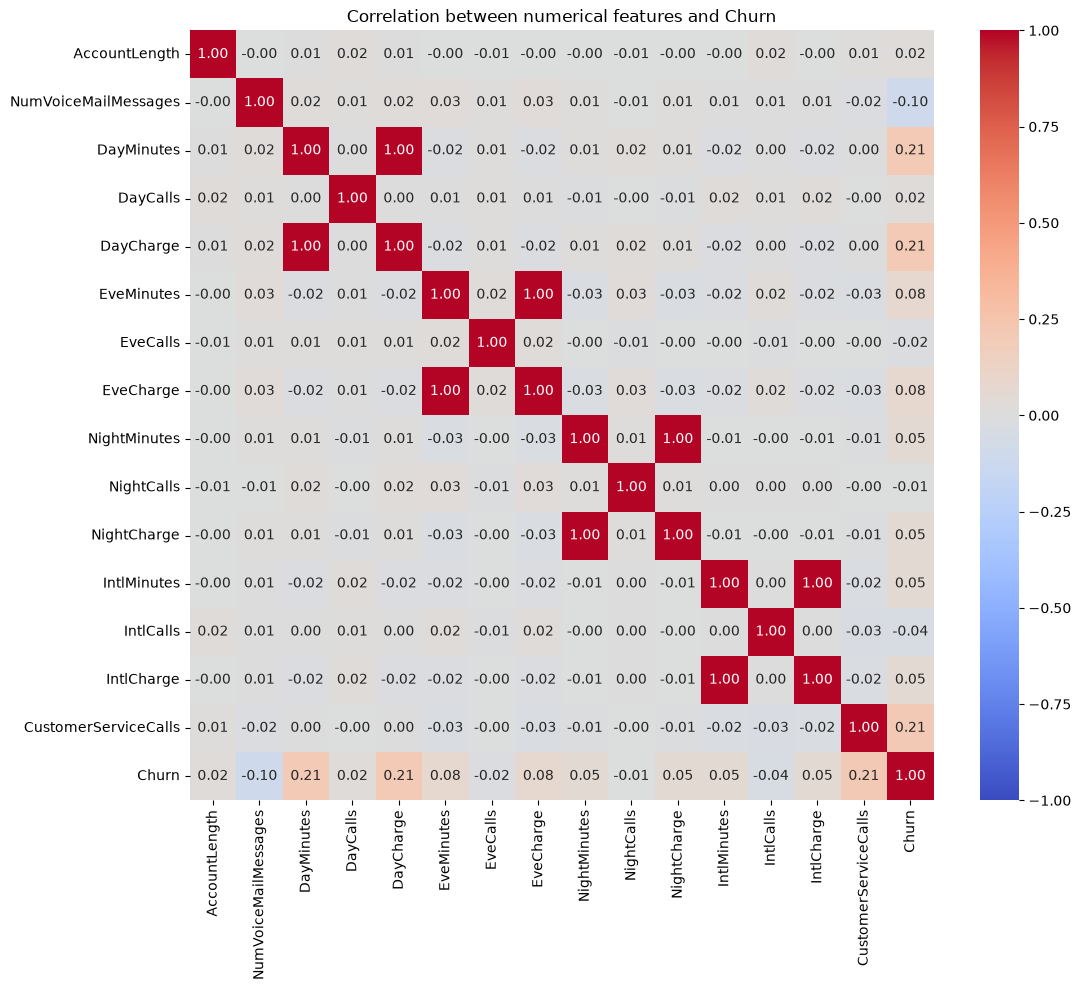

NumVoiceMailMessages   -0.104441
IntlCalls              -0.040553
EveCalls               -0.020547
NightCalls             -0.006029
DayCalls                0.020692
AccountLength           0.023283
NightCharge             0.046981
NightMinutes            0.046984
IntlCharge              0.050525
IntlMinutes             0.050604
EveCharge               0.077339
EveMinutes              0.077347
DayCharge               0.209736
DayMinutes              0.209738
CustomerServiceCalls    0.214686
Name: Churn, dtype: float64


In [7]:
# Correlation matrix and heatmap of numeric_features
corr = train[numeric_features + ["Churn"]].corr() # compute correlation matrix for all features and target
plt.figure(figsize=(12, 10)) # set fig size
sns.heatmap(corr, annot=True, # gives each cell its numeric value
            fmt=".2f", # format numbers to 2 decimal places
            cmap="coolwarm", 
            vmin=-1, 
            vmax=1) 
plt.title("Correlation between numerical features and Churn")
plt.show() 

print(corr["Churn"].drop("Churn").sort_values())   # correlation of each feature with Churn

# Correlation with Churn (all weak, none above 0.25):
# - weak positive: CustomerServiceCalls (0.21), DayMinutes / DayCharge (0.21)
# - very weak positive: EveMinutes / EveCharge (0.08)
# - weak negative: NumVoiceMailMessages (-0.10)
# - the rest are close to 0 (between -0.05 and 0.05)
#
# Multicollinearity: each Minutes column and its Charge column (Day, Eve, Night, Intl)
# carry the same information (Charge is about Minutes x a fixed price), which is why
# they have practically identical correlations with Churn. We therefore drop the
# Charge columns in the preprocessing step.

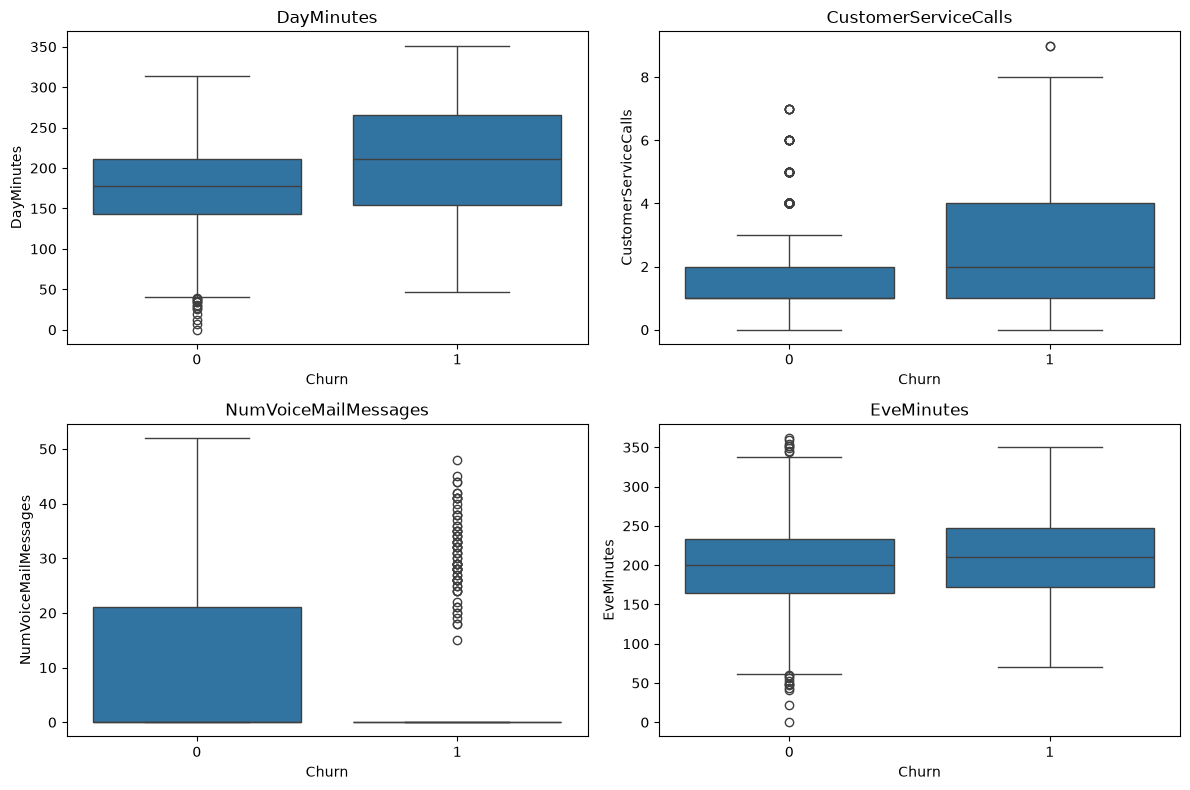

In [8]:
# Boxplot for selected numerical features 
selected_features = ["DayMinutes", "CustomerServiceCalls", "NumVoiceMailMessages", "EveMinutes"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), selected_features):
     sns.boxplot(data=train, x="Churn", y=col, ax=ax)
     ax.set_title(col)

plt.tight_layout()
plt.show()

# 1- DayMinutes : customers who churn (1) have higher median and distribution of DayMinutes than the ones who don't 
# 2- CustomerServiceCalls : customers who churn generally have more CustomerServiceCalls
# 3- NumVoiceMailMessages concentrated around 0, customers who churn generally show less NumVoiceMailMessages, but there are many outliers as well
# 4- EveMinutes distributions are roughly similar 

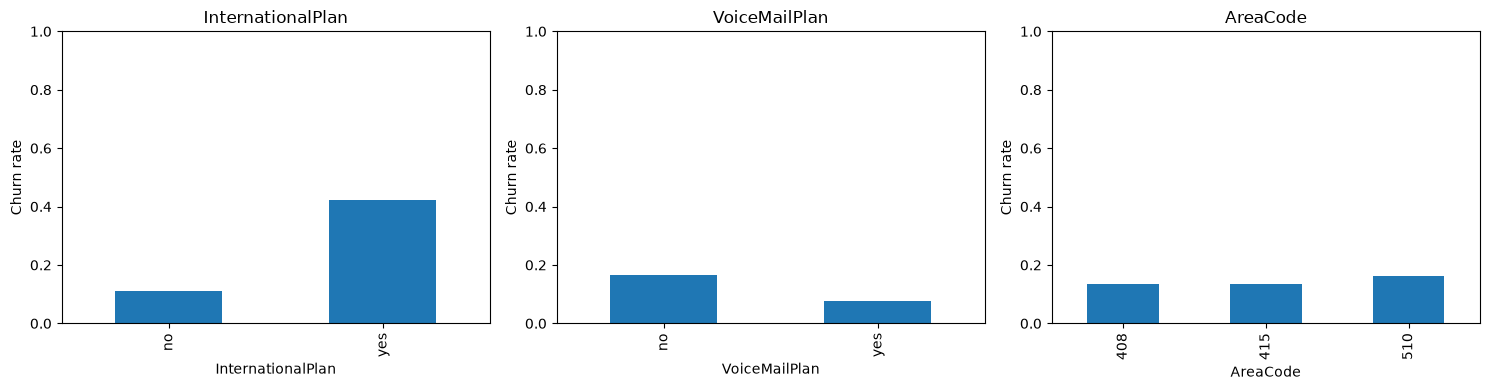

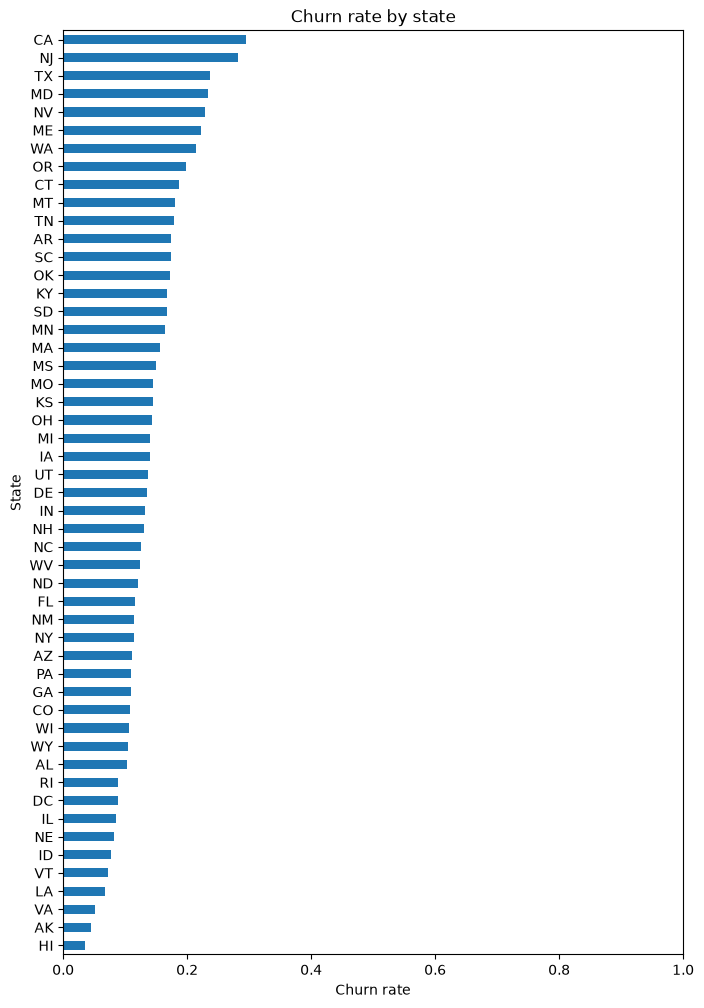

In [9]:
# Compare churn rates across all categorical_features
# state would need a horizontal plot for readability since it has 51 types 
# selected_categories
selected_categories = ["InternationalPlan", "VoiceMailPlan", "AreaCode"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, selected_categories):
    churn_rate = train.groupby(col)["Churn"].mean()
    churn_rate.plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Churn rate")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

# state 
# Churn rate for each state
state_churn = train.groupby("State")["Churn"].mean()

# Plot states horizontally for readability
state_churn.sort_values().plot(kind="barh", figsize=(8, 12))

plt.title("Churn rate by state")
plt.xlabel("Churn rate")
plt.ylabel("State")
plt.xlim(0, 1)
plt.show()

# more InternationalPlan is related to more churn rates 
# having Voicemailplan seems related to lower churn rate
# AreaCode shows relatively small differences between types
# State also shows considerable variation, but with only about 70 customers per state the churn rates are noisy,
# so the differences between states may be largely random


### 4. Data cleaning

In [10]:
# Already checked, no missing or negative values or duplicated ids 
print("Missing values in test:", test.isnull().sum().sum())
print("Duplicate customer IDs:", train["CustomerId"].duplicated().sum())
print("Negative numerical values:", (train[numeric_features] < 0).sum().sum())

Missing values in test: 0
Duplicate customer IDs: 0
Negative numerical values: 0


### 5. Data preprocessing

In [11]:
# Feature engineering: TotalCharge = the customer's total phone bill
# Customers with a high total bill are more likely to leave, but a tree can only split on one
# column at a time, so it can't easily add four columns together itself. We give it the sum directly.
# It is added to both train and test, so the Kaggle predictions get the same feature.
for df in (train, test):
    df["TotalCharge"] = df["DayCharge"] + df["EveCharge"] + df["NightCharge"] + df["IntlCharge"]

# addressing the minutes-charges multicollinearity
charge_features = ["DayCharge", "EveCharge", "NightCharge", "IntlCharge"] # excluding the four charge features
numeric_features = [col for col in numeric_features if col not in charge_features] # creating the new numeric_features
numeric_features = numeric_features + ["TotalCharge"] # adding the new total bill feature

# dropping State (51 categories with only about 70 customers each, so noisy)
# and AreaCode (almost no difference in churn rate between the 3 area codes, see section 3)
categorical_features = ["InternationalPlan", "VoiceMailPlan"]

# combining predictors
features = numeric_features + categorical_features
# 12 numerical and 2 categorical features

# creating feature matrix
X = train[features]
y = train["Churn"]
print(X.shape, y.shape)

(3500, 14) (3500,)


In [12]:
# # addressing the minutes-charges multicollinearity
# charge_features = ["DayCharge", "EveCharge", "NightCharge", "IntlCharge"] # excluding charge features 
# numeric_features = [col for col in numeric_features if col not in charge_features] # creating the new numeric_features 

# # combining predictors
# features = numeric_features + categorical_features 
# # 11 numerical and 4 categorical features 

# # creating feature matrix 
# X = train[features]
# y = train["Churn"]
# print(X.shape, y.shape)

In [13]:
# Splitting the data into 60% training and 40% holdout
X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

print(X_train.shape, X_holdout.shape)

(2100, 14) (1400, 14)


In [14]:
from sklearn.preprocessing import OneHotEncoder

# Define preprocessing for each feature type
numeric_scaler = StandardScaler()
categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

from sklearn.compose import ColumnTransformer

# Apply different preprocessing to numerical and categorical features
preprocessor = ColumnTransformer([("num", numeric_scaler, numeric_features), ("cat", categorical_encoder, categorical_features)])

### 6. Evaluating different models and hyperparameters (using cross-validation)

In [15]:
from sklearn.pipeline import Pipeline                 # chains preprocessing + model into one object
from sklearn.decomposition import PCA                 # dimension reduction
from sklearn.model_selection import StratifiedKFold, GridSearchCV  # cross-validation and hyperparameter tuning

# 5-fold stratified cross-validation: the 60% training part is split into 5 folds,
# each fold keeps the same churn ratio (about 14% churners) as the full data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# All tuning below uses only X_train / y_train (60%).
# X_holdout / y_holdout (40%) is kept untouched for the final evaluation in section 7.

In [16]:
# Pipeline 1: preprocessing -> PCA (dimension reduction) -> SVC with RBF kernel
pipe_svc = Pipeline([
    ("prep", preprocessor),                 # scale numeric + one-hot encode categorical
    ("pca", PCA(random_state=42)),          # reduce the 16 columns to fewer components
    ("svc", SVC(kernel="rbf")),             # kernel SVM
])

# Hyperparameters to try (names are "<step name>__<parameter>")
param_grid_svc = {
    "pca__n_components": [4, 6, 8, 10, 12, 14],  # number of PCA components to keep (max 16 columns)
    "svc__C": [1, 10, 100],                 # regularisation strength (higher C = less regularisation)
    "svc__gamma": ["scale", 0.01, 0.1],     # how far the influence of one training point reaches
    "svc__class_weight": [None, "balanced"],  # "balanced" gives the rare churn class more weight
}

gs_svc = GridSearchCV(pipe_svc, param_grid_svc, scoring="f1_macro", cv=cv, n_jobs=-1)
gs_svc.fit(X_train, y_train)

print("Best parameters:", gs_svc.best_params_)
print("Best CV macro F1:", round(gs_svc.best_score_, 3))

Best parameters: {'pca__n_components': 12, 'svc__C': 1, 'svc__class_weight': 'balanced', 'svc__gamma': 0.1}
Best CV macro F1: 0.81


In [17]:
# Pipeline 2: preprocessing -> logistic regression with L1 or L2 regularisation
# Note: in scikit-learn 1.9 the old penalty="l1"/"l2" argument is deprecated.
# l1_ratio=0 means L2 (ridge) and l1_ratio=1 means L1 (lasso).
pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("lr", LogisticRegression(solver="saga", max_iter=5000)),  # saga supports both L1 and L2
])

param_grid_lr = {
    "lr__l1_ratio": [0, 1],                 # 0 = L2 regularisation, 1 = L1 regularisation
    "lr__C": [0.01, 0.1, 1, 10, 100],       # inverse regularisation strength (small C = strong regularisation)
    "lr__class_weight": [None, "balanced"],
}

gs_lr = GridSearchCV(pipe_lr, param_grid_lr, scoring="f1_macro", cv=cv, n_jobs=-1)
gs_lr.fit(X_train, y_train)

print("Best parameters:", gs_lr.best_params_)
print("Best CV macro F1:", round(gs_lr.best_score_, 3))


Best parameters: {'lr__C': 0.1, 'lr__class_weight': 'balanced', 'lr__l1_ratio': 1}
Best CV macro F1: 0.662


In [18]:
# Extra model: random forest (ensemble of decision trees)
# Trees don't need scaling, but using the same preprocessor keeps the pipelines comparable
pipe_rf = Pipeline([
    ("prep", preprocessor),
    ("rf", RandomForestClassifier(random_state=42)),
])

param_grid_rf = {
    "rf__n_estimators": [200, 500],         # number of trees
    "rf__max_depth": [None, 10, 20],        # how deep each tree can grow (None = no limit)
    "rf__min_samples_leaf": [1, 3],         # minimum customers in each leaf
    "rf__class_weight": [None, "balanced"],
}

gs_rf = GridSearchCV(pipe_rf, param_grid_rf, scoring="f1_macro", cv=cv, n_jobs=-1)
gs_rf.fit(X_train, y_train)

print("Best parameters:", gs_rf.best_params_)
print("Best CV macro F1:", round(gs_rf.best_score_, 3))

Best parameters: {'rf__class_weight': None, 'rf__max_depth': 10, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 200}
Best CV macro F1: 0.946


In [19]:
# Compare the best cross-validated macro F1 of each model
results = pd.DataFrame({
    "Model": ["PCA + SVC (RBF kernel)", "Logistic regression (L1/L2)", "Random forest"],
    "Best CV macro F1": [gs_svc.best_score_, gs_lr.best_score_, gs_rf.best_score_],
}).sort_values("Best CV macro F1", ascending=False)

print(results.round(3).to_string(index=False))

# Random forest has the highest CV macro F1 (0.946), followed by PCA + SVC (0.810).
# Logistic regression is clearly worst (0.662): it can only draw a straight decision boundary,
# while churn depends on non-linear patterns (e.g. churn jumps for customers with many
# customer service calls or a very high total bill).
# Adding TotalCharge raised the random forest from 0.854 to 0.946: trees split on one column
# at a time and could not build the total bill from the four separate charge columns themselves.
# We choose the random forest as our final model for section 7 and the Kaggle submission.

                      Model  Best CV macro F1
              Random forest             0.946
     PCA + SVC (RBF kernel)             0.810
Logistic regression (L1/L2)             0.662


### 7. Final evaluation

### 8. Kaggle submission

The submission format is taken from the example code on the competition's Overview page: a column named `Quality`, with the DataFrame index named `ID`, written out so that the row numbers 0 to 208 become the ID column.

This is worth stating because two other sources in the folder point elsewhere. `sample_submission.csv` carries the right IDs but spells the target `quality` in lower case, and an upload in that form is rejected. The `Id` column in `test.csv`, which runs 1117, 1411 and so on, is not what the scorer keys on either.

No cleaning is applied to `test.csv`. Every row has to receive a prediction, so removing duplicates or outliers there would leave gaps the submission cannot have. Selecting `test[features]` preserves the original row order, so prediction *i* belongs to row *i*.

In [20]:
# Submission format copied from the example code on the competition's Overview page:
#     y_test = pd.DataFrame(y_test, columns=["Quality"])
#     y_test.index.name = "Id"
#     y_test[['Quality']].to_csv("submission.csv")
y_pred_kaggle = best_model.predict(X_test)

y_test = pd.DataFrame(y_pred_kaggle, columns=["quality"])
y_test.index.name = "Id"                     # row numbers 0..208 become the ID column
y_test[["quality"]].to_csv("submission.csv")

# checks before uploading
check = pd.read_csv("submission.csv")
sample = pd.read_csv("sample_submission.csv")
print("header:            ", ",".join(check.columns))
print("shape:             ", check.shape, "  (expected (209, 2))")
print("IDs match sample:  ", check["Id"].tolist() == sample["ID"].tolist())
print("missing values:    ", int(check.isna().sum().sum()))
print("predicted classes: ", check["quality"].value_counts().to_dict())
print()
print(check.head().to_string(index=False))

NameError: name 'best_model' is not defined